In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

# 1D integration with equispaced points: trapezoidal & Simpson rules

In [2]:
def Trapezio(fun, n, x0, xn):

    ascissa = np.linspace(x0, xn, num = n)
    h = (xn - x0)/(n - 1)
    ordinata = fun(ascissa)
    ordinata[0] = 0.5 * ordinata[0]
    ordinata[-1] = 0.5 * ordinata[-1]

    return h * ordinata.sum()

In [3]:
stima = Trapezio(np.exp, 100, 0, 1)
vero = np.exp(1) - 1
errore = abs(stima - vero)

print(f'valore stimato: {stima} \nvalore vero: {vero} \nerrore: {errore}')

valore stimato: 1.718296438183449 
valore vero: 1.718281828459045 
errore: 1.4609724403813473e-05


In [4]:
stime = []
punti = []
andamento = []

for i in range(1,20):

    punto = 2**i
    stime.append(Trapezio(np.exp, punto, 0, 1))
    punti.append(punto)
    andamento.append(1/(punto**2))

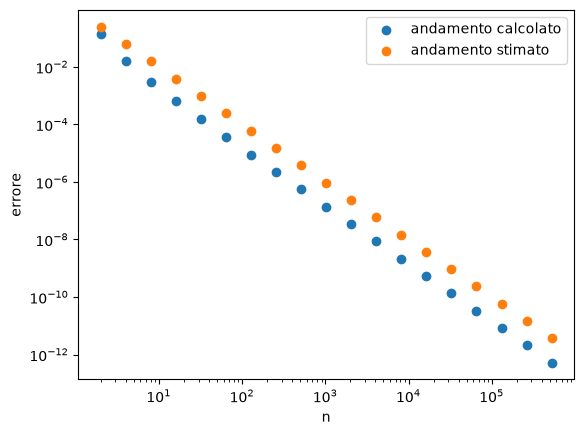

In [5]:
plt.scatter(punti, abs(stime - vero), label='andamento calcolato')
plt.scatter(punti, andamento, label='andamento stimato')
plt.ylabel('errore')
plt.xlabel('n')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

# 1D integration: Gaussian Quadrature

In [6]:
deggauss = []

for deg in range(1,10):
    
    x, w = np.polynomial.legendre.leggauss(deg)
    integral = np.sum(w * np.exp(x))
    deggauss.append(integral)


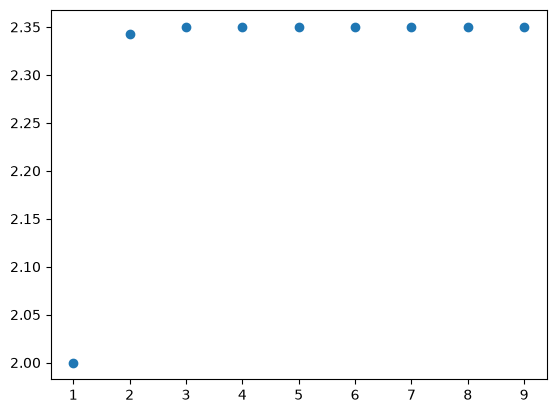

In [7]:
plt.scatter(list(range(1,10)), deggauss)
plt.show()

# 2D integration

In [8]:
def d_function(x,y):

    value = x**2 + 6*x*y + y**2

    return value

def d_integration(fun, a, b, c, d, n=2, m=2):

    valori = []

    delta_x = (b - a)/(n - 1)
    delta_y = (d - c)/(m - 1)

    for i in range(n):

        medio_x = a + (i + 0.5)*delta_x

        for j in range(m):

            medio_y = c + (j + 0.5)*delta_y

            valori.append(fun(medio_x, medio_y))

    return sum(valori) * delta_x * delta_y

        

In [9]:
punti = []
stime = []

for i in range(1,10):

    punto = 2**i
    punti.append(punto)
    stime.append(d_integration(d_function, -1, 1, -1, 1, n=punto, m=punto))

stime = np.array(stime)

In [10]:
vero = 8/3

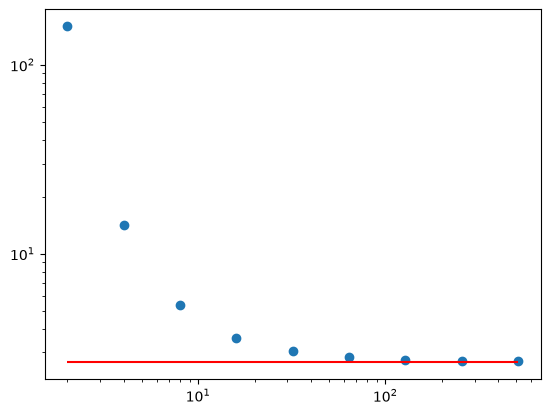

In [11]:
plt.scatter(punti, stime)
plt.hlines(vero, min(punti), max(punti), colors='red')
plt.xscale('log')
plt.yscale('log')
plt.show()

# Monte Carlo method: generic sample mean and importance sampling

In [14]:
stime = []
punti = []

for i in range(1, 10):

    punto = 2**i
    x = np.linspace(0,1, num=punto)
    x = -x**2
    stime.append(np.mean(np.exp(x)))
    punti.append(punto)

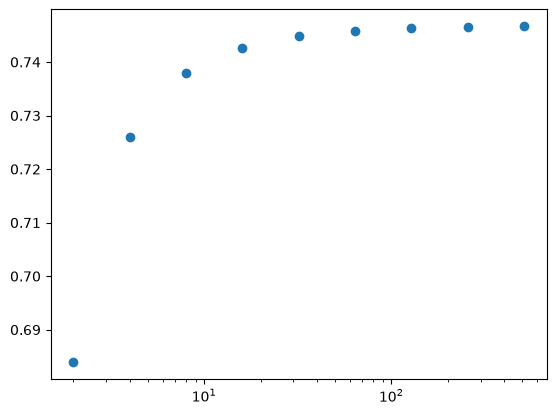

In [15]:
plt.scatter(punti, stime)
plt.xscale('log')
plt.show()

In [ ]:
# 1. Generate points according to p(x) = e^(-x) using Inverse Transform Sampling
        # Uniform random variables u ~ Uniform(0, 1)
        u = np.random.uniform(0, 1, N)
        # Inverse CDF of exponential distribution: x = -ln(1 - u)
        x_samples = -np.log(1.0 - u)
        
        # p(x) for the generated samples
        p_x = np.exp(-x_samples)
        
        # Importance sampling estimator: (1/N) * sum( f(xi) / p(xi) )
        # Since p(xi) = exp(-xi), f(xi)/p(xi) = f(xi) / exp(-xi)
        weights = target_function(x_samples) / p_x
        estimate = np.mean(weights)
        variance = np.var(weights) / N